# Transfer learning for kidney CT classification: a comparison of five ImageNet CNNs

**Siddhartha Sitaula** · [github.com/sidsitaulaa](https://github.com/sidsitaulaa) · [siddharthasitaula.com.np](https://siddharthasitaula.com.np)

*Companion notebook to this repository. It reads the saved outputs in `results/image_level/` and rebuilds every table and figure. It needs only `pandas`, `numpy` and `matplotlib`: no TensorFlow, no GPU and no dataset download. The training code is shown in clearly marked cells that are **not executed** here (see Section 4.6).*

## Abstract

This notebook presents the code and results of our research project on kidney CT classification [11]. It compares five ImageNet-pretrained convolutional networks (VGG16, MobileNet, ResNet50, InceptionV3 and Xception) for classifying kidney CT slices as **Cyst, Normal, Stone or Tumor**. Each network is used as a frozen feature extractor: 150×150 input, global max pooling, and a Dense–BatchNorm–Dropout head tuned with keras-tuner random search. The data are split 70/15/15 into train, validation and test sets by image, with byte-identical files kept together. Hyperparameters are chosen on the validation set, each network receives its own preprocessing, metrics are computed on predicted labels, and each test set is used once. All five models score between **98.70% and 99.89%** test accuracy. ResNet50 is best (99.89%, 95% CI 99.73–100%), followed by VGG16 (99.84%) and MobileNet (99.73%, 99.46–99.95%). These scores are **not** a measure of performance on new patients: 99.9% of test images come from a CT scan that also has slices in the training set, and 97.4% have a near-identical training image. They measure how well a model recognises other slices of scans it has already seen. When whole scans are held out, the same frozen backbones reach only 56–67%, and a fine-tuned MobileNet ensemble reaches about 81% (`results/REPORT.md`, `results/IMPROVEMENTS.md`).

## Contents

1. Background and motivation
2. Setup: load the saved results
3. Dataset
4. Methods (pipeline, preprocessing, head, hyperparameter search, training, code)
5. Train / validation / test split
6. Evaluation protocol
7. Results
8. Discussion
9. Limitations
10. Reproducibility
11. Conclusion
12. References

## 1. Background and motivation

Kidney cysts, stones and tumours are common findings on abdominal CT. A model that flags them could help triage reads. The public *CT KIDNEY DATASET: Normal-Cyst-Tumor-Stone* (Islam et al., 2022 [1]) has become a standard benchmark for this task. Many papers report accuracy of about 99% on it, usually with ImageNet-pretrained CNNs [2–7] used as feature extractors or fine-tuned.

This study follows that pattern. It compares VGG16 [3], MobileNet [4], ResNet50 [5], InceptionV3 [6] and Xception [7] with frozen ImageNet weights and a small dense head tuned with KerasTuner [8]. The evaluation uses a held-out test set, validation-only model selection, each network's own preprocessing and label-based metrics (Section 6). This notebook answers a narrow question:

> **With an image-level split, frozen backbones and a tuned dense head, what test accuracy do the five networks reach, and how do they compare?**

A second, more important question is whether such a number means anything for new patients. Slice-level splits of volumetric scans are a well-known source of data leakage [9, 10]. Section 9 quantifies this leakage for the present split and points to the scan-level evaluation in `results/REPORT.md`.

## 2. Setup: load the saved results

All inputs come from `results/image_level/`, which `scripts/run_image_level.py` writes:

| File | Content |
|---|---|
| `summary.csv` | one row per model: test metrics, accuracy CI, selected hyperparameters |
| `<Model>/metrics.json` | full metrics, confusion matrix, timings |
| `<Model>/predictions.csv` | test-set class probabilities for every image (1,853 rows) |
| `<Model>/history.csv` | per-epoch loss and accuracy of the final 10-epoch refit |
| `<Model>/tuner_trials.csv` | the 10 keras-tuner trials and their validation accuracy |
| `split.csv`, `split_summary.json` | the train/val/test assignment of all 12,446 images and leakage statistics |
| `input_checks.json`, `input_check.png`, `sanity_check.json` | data-pipeline audits |

In [1]:
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
RES = ROOT / "results" / "image_level"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

MODELS = ["VGG16", "MobileNet", "ResNet50", "InceptionV3", "Xception"]
CLASSES = ["Cyst", "Normal", "Stone", "Tumor"]

# Okabe-Ito colour-blind-safe palette
OI = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "pink": "#CC79A7",
      "sky": "#56B4E9", "vermillion": "#D55E00", "yellow": "#F0E442", "grey": "#7F7F7F"}
MODEL_COLOR = dict(zip(MODELS, [OI["blue"], OI["orange"], OI["green"], OI["pink"], OI["sky"]]))
CLASS_COLOR = dict(zip(CLASSES, [OI["blue"], OI["green"], OI["orange"], OI["vermillion"]]))
SUBSET_COLOR = {"train": OI["blue"], "val": OI["orange"], "test": OI["green"]}

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "savefig.dpi": 180, "figure.dpi": 100, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
})


def save(fig, name):
    fig.savefig(FIG / name)
    print("saved figures/" + name)


summary = pd.read_csv(RES / "summary.csv").set_index("model").loc[MODELS]
metrics = {m: json.loads((RES / m / "metrics.json").read_text()) for m in MODELS}
preds = {m: pd.read_csv(RES / m / "predictions.csv") for m in MODELS}
history = {m: pd.read_csv(RES / m / "history.csv") for m in MODELS}
trials = {m: pd.read_csv(RES / m / "tuner_trials.csv", dtype={"trial": str}) for m in MODELS}
split = pd.read_csv(RES / "split.csv")
split_summary = json.loads((RES / "split_summary.json").read_text())
input_checks = json.loads((RES / "input_checks.json").read_text())
sanity = json.loads((RES / "sanity_check.json").read_text())
environment = json.loads((RES / "environment.json").read_text())
print(f"loaded {len(MODELS)} models, {len(split):,} images in split.csv, "
      f"{len(preds['VGG16']):,} test predictions per model")

loaded 5 models, 12,446 images in split.csv, 1,853 test predictions per model


## 3. Dataset

**Source.** *CT KIDNEY DATASET: Normal-Cyst-Tumor-Stone*, collected from hospitals in Dhaka, Bangladesh, and published with Islam et al. (2022) [1]. It is available on [Kaggle](https://www.kaggle.com/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone), and `scripts/download_data.py` can also fetch it from a [Hugging Face mirror](https://huggingface.co/datasets/mhmad240/kidney-ct-classification). The script checks the class counts against the Kaggle release. The images are not redistributed here.

**Content.** 12,446 JPEG slices from whole-abdomen and urogram CT, in axial and coronal views, in four classes. There are no patient or scan identifiers. Consecutive file numbers are neighbouring slices of the same scan, which matters for the split (Section 9).

In [2]:
counts = split["class"].value_counts().reindex(CLASSES)
ds = pd.DataFrame({"images": counts, "share": (counts / counts.sum()).map("{:.1%}".format)})
ds.loc["Total"] = [counts.sum(), "100.0%"]
display(ds)

audit = input_checks["audit"]
print(f"formats: {audit['formats']}, colour modes: {audit['modes']}, bit depth: {audit['bit_depth_per_channel']}")
print(f"decode failures: {len(audit['decode_failures'])}; grey slices stored as RGB "
      f"(identical channels in {audit['sampled_rgb_with_identical_channels']} sampled files)")
print(f"{audit['distinct_sizes']} distinct sizes; width {audit['width_range'][0]}-{audit['width_range'][1]} px, "
      f"height {audit['height_range'][0]}-{audit['height_range'][1]} px; "
      f"aspect ratio w/h {audit['aspect_ratio_w_over_h']['min']:.2f}-{audit['aspect_ratio_w_over_h']['max']:.2f}")
print("most common sizes:", ", ".join(f"{s} ({n:,})" for s, n in audit["most_common_sizes"][:5]))

,images,share
class,,
Cyst,3709,29.8%
Normal,5077,40.8%
Stone,1377,11.1%
Tumor,2283,18.3%
Total,12446,100.0%


formats: {'JPEG': 12446}, colour modes: {'RGB': 12446}, bit depth: {'8': 12446}
decode failures: 0; grey slices stored as RGB (identical channels in 249 of 249 sampled files)
77 distinct sizes; width 512-1371 px, height 451-1110 px; aspect ratio w/h 1.00-1.24
most common sizes: 512x512 (7,709), 798x646 (240), 804x651 (179), 768x622 (177), 840x680 (171)


Most images (62%) are 512×512, and the rest range up to 1371×1110 px. Every image is resized bilinearly to 150×150 without keeping the aspect ratio. The widest images are squeezed by at most 19%.

**Sample grid.** Below are three training and three test images per class after decoding and resizing, before any network-specific preprocessing. The script saved this grid during its input checks. All slices are upright, none is blank or saturated, and every label matches its folder.

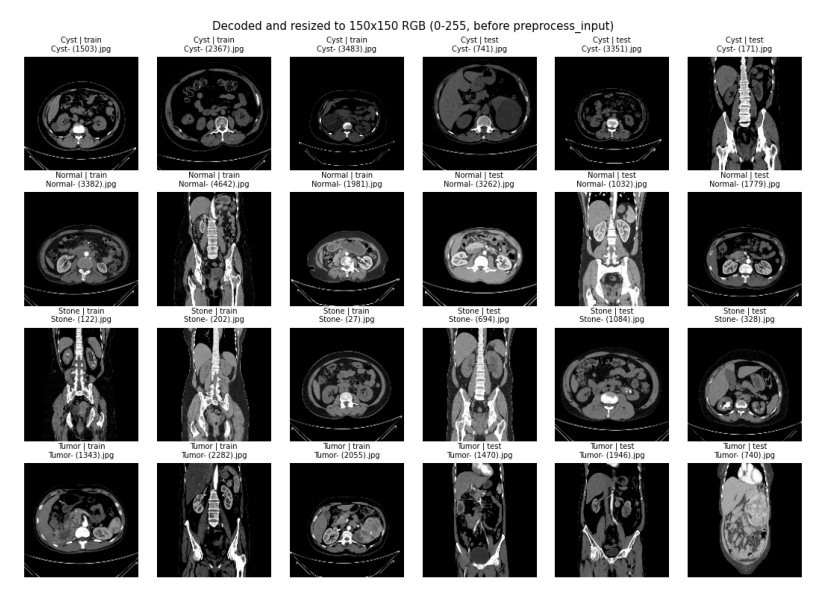

saved figures/sample_images.png (copy of results/image_level/input_check.png)


In [3]:
shutil.copyfile(RES / "input_check.png", FIG / "sample_images.png")
img = plt.imread(FIG / "sample_images.png")
fig, ax = plt.subplots(figsize=(11, 7.5))
ax.imshow(img)
ax.axis("off")
plt.show()
print("saved figures/sample_images.png (copy of results/image_level/input_check.png)")

## 4. Methods

### 4.1 Pipeline

Each JPEG is decoded to 3-channel RGB (`decode_image(channels=3)`) and resized to 150×150 with pixel values kept in 0–255. The network's own `preprocess_input` is then applied **once**. A frozen ImageNet backbone (`include_top=False`, `pooling="max"`) turns the image into a feature vector, and a small trainable head outputs softmax probabilities over the four classes.

saved figures/pipeline.png


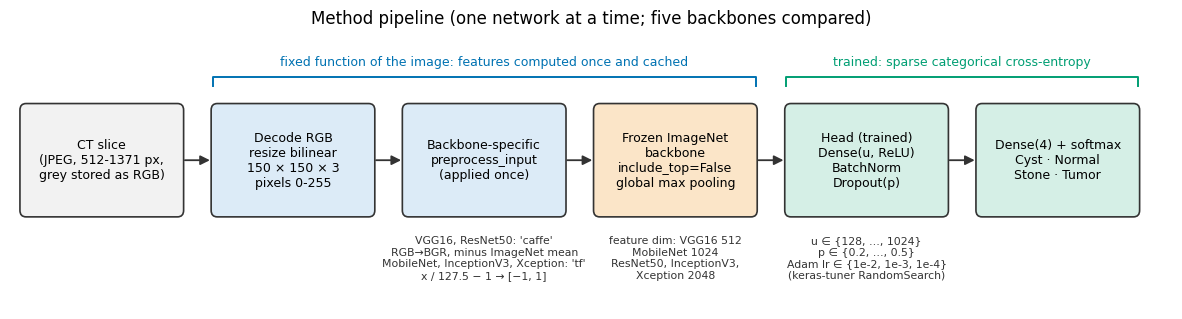

In [4]:
def box(ax, x, y, w, h, text, fc, ec="#333333", fs=9, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal", wrap=True)


def arrow(ax, x0, y0, x1, y1):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=14,
                                 lw=1.3, color="#333333"))


fig, ax = plt.subplots(figsize=(15, 3.6))
ax.set_xlim(0, 15.2)
ax.set_ylim(0.6, 4.0)
ax.axis("off")

W, H, Y = 2.1, 1.35, 1.75
steps = [
    ("CT slice\n(JPEG, 512-1371 px,\ngrey stored as RGB)", "#F2F2F2"),
    ("Decode RGB\nresize bilinear\n150 × 150 × 3\npixels 0-255", "#DCEBF7"),
    ("Backbone-specific\npreprocess_input\n(applied once)", "#DCEBF7"),
    ("Frozen ImageNet\nbackbone\ninclude_top=False\nglobal max pooling", "#FBE5C8"),
    ("Head (trained)\nDense(u, ReLU)\nBatchNorm\nDropout(p)", "#D5EFE6"),
    ("Dense(4) + softmax\nCyst · Normal\nStone · Tumor", "#D5EFE6"),
]
xs = [0.15 + i * 2.5 for i in range(len(steps))]
for x, (t, c) in zip(xs, steps):
    box(ax, x, Y, W, H, t, c)
for x0, x1 in zip(xs[:-1], xs[1:]):
    arrow(ax, x0 + W, Y + H / 2, x1, Y + H / 2)

# annotations under the boxes
ax.text(xs[2] + W / 2, Y - 0.25,
        "VGG16, ResNet50: 'caffe'\nRGB→BGR, minus ImageNet mean\n"
        "MobileNet, InceptionV3, Xception: 'tf'\nx / 127.5 − 1 → [−1, 1]",
        ha="center", va="top", fontsize=7.8, color="#333333")
ax.text(xs[3] + W / 2, Y - 0.25,
        "feature dim: VGG16 512\nMobileNet 1024\nResNet50, InceptionV3,\nXception 2048",
        ha="center", va="top", fontsize=7.8, color="#333333")
ax.text(xs[4] + W / 2, Y - 0.25,
        "u ∈ {128, …, 1024}\np ∈ {0.2, …, 0.5}\nAdam lr ∈ {1e-2, 1e-3, 1e-4}\n(keras-tuner RandomSearch)",
        ha="center", va="top", fontsize=7.8, color="#333333")

# brackets above: cached vs trained
def bracket(x0, x1, y, text, color):
    ax.plot([x0, x0, x1, x1], [y - 0.12, y, y, y - 0.12], color=color, lw=1.4)
    ax.text((x0 + x1) / 2, y + 0.1, text, ha="center", va="bottom", fontsize=9, color=color)

bracket(xs[1], xs[3] + W, Y + H + 0.35, "fixed function of the image: features computed once and cached", OI["blue"])
bracket(xs[4], xs[5] + W, Y + H + 0.35, "trained: sparse categorical cross-entropy", OI["green"])
ax.set_title("Method pipeline (one network at a time; five backbones compared)", fontsize=12, pad=6)
save(fig, "pipeline.png")
plt.show()

### 4.2 Preprocessing per backbone

Each Keras application expects its own input scaling on 0–255 pixels, so each network's own `preprocess_input` is applied exactly once. The statistics below were measured by the training script on a batch of 16 training images, and the expected ranges were asserted.

In [5]:
pp = pd.DataFrame(input_checks["preprocessing_sample_batch"]).set_index("model").loc[MODELS]
pp["feature dim"] = [metrics[m]["feature_dim"] for m in MODELS]
display(pp[["mode", "min", "max", "mean", "std", "feature dim"]].round(2))

,mode,min,max,mean,std,feature dim
model,,,,,,
VGG16,"caffe: RGB->BGR, subtract ImageNet mean per ch...",-123.68,151.06,-79.97,60.59,512
MobileNet,"tf: x/127.5 - 1 -> [-1, 1]",-1.00,1.00,-0.73,0.47,1024
ResNet50,"caffe: RGB->BGR, subtract ImageNet mean per ch...",-123.68,151.06,-79.97,60.59,2048
InceptionV3,"tf: x/127.5 - 1 -> [-1, 1]",-1.00,1.00,-0.73,0.47,2048
Xception,"tf: x/127.5 - 1 -> [-1, 1]",-1.00,1.00,-0.73,0.47,2048


### 4.3 The classifier head

The head architecture:

```
frozen backbone (include_top=False, pooling="max", ImageNet weights, trainable=False)
→ Flatten            # a no-op after global pooling
→ Dense(units, ReLU)
→ BatchNormalization
→ Dropout(rate)
→ Dense(4, softmax)
```

The head is trained with Adam on sparse categorical cross-entropy, with batch size 32 and no data augmentation.

**Cached features.** The backbone is frozen and there is no augmentation, so each image's backbone output never changes during training. The script therefore computes each backbone's 150×150 max-pooled features once and trains the head on them. This is equivalent to training the full stack, because a Keras layer with `trainable=False` runs its BatchNorm in inference mode even during `fit`. The equivalence was checked directly on MobileNet:

In [6]:
pd.Series(sanity).to_frame("value")

,value
model,MobileNet
images,64
max_abs_diff_probabilities_end_to_end_vs_cached,0.0
max_abs_diff_features_recomputed_vs_cache,0.0
max_abs_diff_backbone_training_true_vs_false,0.0
argmax_agreement,1.0
feature_scale_max,6.0
passed,True


### 4.4 Hyperparameter search

The search uses KerasTuner `RandomSearch` [8]. It maximises **validation** accuracy and never sees the test set.

| Hyperparameter | Search space |
|---|---|
| Dense units | 128 to 1024, step 128 |
| Dropout rate | 0.2 to 0.5, step 0.1 |
| Learning rate (Adam) | {1e-2, 1e-3, 1e-4} |
| Trials / executions per trial / epochs | 10 / 3 / 10 |
| Batch size, seed | 32, 123 |

The tuner seed is fixed, so every backbone was offered the same 10 configurations. The best configuration was refitted on the training set for 10 epochs (monitoring the validation set), and that model was evaluated **once** on the test set.

### 4.5 Evaluation

Predictions are argmax labels. We report accuracy with a 95% percentile bootstrap CI over test images (1,000 resamples), balanced accuracy, macro and weighted precision, recall and F1, per-class precision, recall and F1, confusion matrices, and macro one-vs-rest ROC-AUC. In this notebook, all of these are recomputed from `predictions.csv` and checked against the values the training script saved. The bootstrap CI for macro-F1 is computed here for the first time.

### 4.6 Training code (shown for reference, **not executed** in this notebook)

The cells below are tagged `skip-execution`. They show how the saved results were produced. Run them through `scripts/run_image_level.py` (locally or in Docker) or through `notebooks/image_level_colab.ipynb` (on a Colab GPU), not from here. They need TensorFlow 2.15, keras-tuner 1.4.7 and the dataset.

In [ ]:
# NOT EXECUTED HERE - reference only. Full implementation: scripts/run_image_level.py
import tensorflow as tf
from tensorflow.keras import layers
import keras_tuner as kt

IMG = 150
BACKBONES = {"VGG16": tf.keras.applications.VGG16, "MobileNet": tf.keras.applications.MobileNet,
             "ResNet50": tf.keras.applications.ResNet50, "InceptionV3": tf.keras.applications.InceptionV3,
             "Xception": tf.keras.applications.Xception}

def backbone(name):
    net = BACKBONES[name](include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3), pooling="max")
    net.trainable = False          # frozen: BatchNorm stays in inference mode
    return net

def decode_resize(path):           # 0-255 float32, 3 channels, 150x150 bilinear
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(tf.cast(img, tf.float32), (IMG, IMG))

# features = backbone(name).predict(preprocess_input(decode_resize(path)))  -> cached once per model

In [ ]:
# NOT EXECUTED HERE - reference only (scripts/run_image_level.py, function `build`)
def build(hp):
    model = tf.keras.Sequential([
        layers.Input(shape=(feature_dim,)),
        layers.Flatten(),
        layers.Dense(units=hp.Int("dense_units", min_value=128, max_value=1024, step=128), activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(rate=hp.Float("dropout_rate", min_value=0.2, max_value=0.5, step=0.1)),
        layers.Dense(4, activation="softmax"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(hp.Choice("learning_rate", values=[1e-2, 1e-3, 1e-4])),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

tuner = kt.RandomSearch(build, objective="val_accuracy", max_trials=10, executions_per_trial=3,
                        seed=123, directory="results/image_level/tuner", project_name=f"{name}_hyperparameter_tuning")
tuner.search(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val))
best = build(tuner.get_best_hyperparameters(1)[0])
best.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_val, y_val))
probabilities = best.predict(X_test)        # the test set is used once, here

In [ ]:
# NOT EXECUTED HERE - how to reproduce results/image_level/ from a shell (see Section 10)
#   docker build -f docker/Dockerfile.image_level -t kidney-image-level:2.15 docker/
#   docker run --rm --memory=3g --memory-swap=3g --cpus=4 -v "$PWD":/work -w /work \
#       kidney-image-level:2.15 python scripts/run_image_level.py

## 5. Train / validation / test split

The split is a **stratified 70/15/15 split by image** (seed 123), built from the file list and saved to `split.csv`. The script asserts that the three subsets are disjoint. The dataset contains 1,034 files that are byte-identical copies, forming 517 groups with the same MD5 hash. Each group is assigned to a single subset, so no test image has an exact copy in training. The split is image-level, and Section 9 explains why that matters.

In [7]:
tab = pd.crosstab(split["class"], split["subset"]).reindex(index=CLASSES, columns=["train", "val", "test"])
tab.loc["Total"] = tab.sum()
pct = tab.div(tab.sum(axis=1), axis=0)
display(tab.astype(str) + " (" + (pct * 100).round(1).astype(str) + "%)")
print(f"duplicate groups kept together: {split_summary['duplicate_groups']} "
      f"({split_summary['files_in_duplicate_groups']} files); "
      f"test images byte-identical to a training image: {split_summary['test_byte_identical_in_train']}")

subset,train,val,test
class,,,
Cyst,2599 (70.1%),564 (15.2%),546 (14.7%)
Normal,3552 (70.0%),768 (15.1%),757 (14.9%)
Stone,964 (70.0%),206 (15.0%),207 (15.0%)
Tumor,1598 (70.0%),342 (15.0%),343 (15.0%)
Total,8713 (70.0%),1880 (15.1%),1853 (14.9%)


duplicate groups kept together: 517 (1034 files); test images byte-identical to a training image: 0


saved figures/split.png


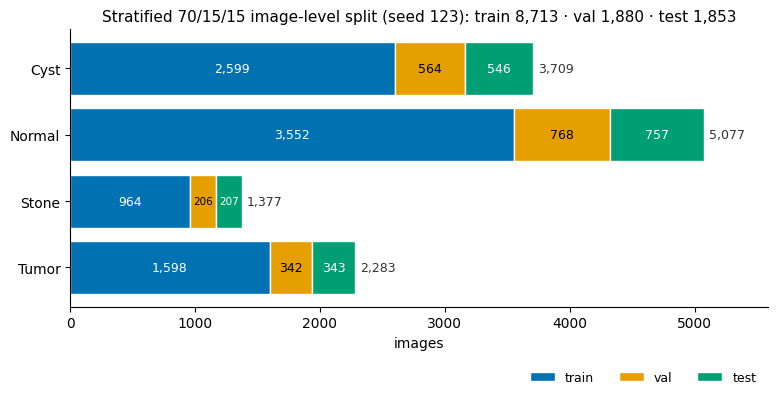

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
rows = CLASSES[::-1]
left = np.zeros(len(rows))
for s in ["train", "val", "test"]:
    vals = tab.loc[rows, s].to_numpy()
    ax.barh(rows, vals, left=left, color=SUBSET_COLOR[s], edgecolor="white", label=s)
    for y, (l, v) in enumerate(zip(left, vals)):
        ax.text(l + v / 2, y, f"{v:,}", ha="center", va="center", fontsize=9 if v > 300 else 7.5,
                color="white" if s != "val" else "black")
    left += vals
for y, tot in enumerate(left):
    ax.text(tot + 40, y, f"{int(tot):,}", va="center", fontsize=9, color="#333333")
ax.set_xlabel("images")
ax.set_xlim(0, left.max() * 1.1)
ax.set_title(f"Stratified 70/15/15 image-level split (seed 123): "
             f"train {split_summary['n_train']:,} · val {split_summary['n_val']:,} · test {split_summary['n_test']:,}")
ax.legend(ncol=3, loc="lower right", frameon=False, bbox_to_anchor=(1.0, -0.32))
save(fig, "split.png")
plt.show()

## 6. Evaluation protocol

| Step | Protocol |
|---|---|
| Split | Stratified 70/15/15 train/val/test split by image (seed 123). The three subsets are asserted to be disjoint, and byte-identical files are kept in one subset |
| Model selection | keras-tuner RandomSearch on the validation set only (10 trials × 3 executions × 10 epochs). The test set is used once per model |
| Preprocessing | Each network's own `preprocess_input`, applied once to 0–255 pixels |
| Metrics | Computed on argmax labels: accuracy with bootstrap CI, balanced accuracy, macro and weighted precision/recall/F1, per-class metrics, confusion matrices, ROC-AUC |
| Models | VGG16, MobileNet, ResNet50, InceptionV3 and Xception, with ImageNet weights |
| Fixed settings | 150×150 input, frozen backbone, global max pooling, 10-epoch refit of the best head, batch size 32 |

## 7. Results

### 7.1 Recomputing the metrics from the saved predictions

As a check, every headline number is recomputed from `predictions.csv` and compared with what the training script stored in `metrics.json`: the confusion matrix, accuracy, macro-F1, ROC-AUC, and the accuracy CI using the same bootstrap seed. The macro-F1 bootstrap CI is new here. It uses the same 1,000 resamples of test images.

In [9]:
K = len(CLASSES)


def confusion(y, p):
    return np.bincount(y * K + p, minlength=K * K).reshape(K, K)


def macro_f1_from_cm(cm):
    tp = np.diag(cm).astype(float)
    prec = np.divide(tp, cm.sum(0), out=np.zeros(K), where=cm.sum(0) > 0)
    rec = np.divide(tp, cm.sum(1), out=np.zeros(K), where=cm.sum(1) > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(K), where=(prec + rec) > 0)
    return f1.mean(), prec, rec, f1


def roc_curve(y_bin, score):
    order = np.argsort(-score, kind="mergesort")
    s, y = score[order], y_bin[order]
    idx = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]
    tps = np.cumsum(y)[idx]
    fps = idx + 1 - tps
    tpr = np.r_[0, tps / y.sum()]
    fpr = np.r_[0, fps / (len(y) - y.sum())]
    trapz = getattr(np, "trapezoid", None) or np.trapz
    return fpr, tpr, float(trapz(tpr, fpr))


N_BOOT, SEED = 1000, 123
rows, roc = [], {}
for m in MODELS:
    df = preds[m]
    y, P = df["y_true"].to_numpy(), df[[f"p_{c}" for c in CLASSES]].to_numpy()
    yp = P.argmax(1)
    assert (yp == df["y_pred"].to_numpy()).all()
    cm = confusion(y, yp)
    assert cm.tolist() == metrics[m]["confusion_matrix"], m
    mf1, prec, rec, f1 = macro_f1_from_cm(cm)
    acc = (y == yp).mean()

    # same resampling as kidney_tl.image_level.bootstrap_accuracy_ci (seed 123, as in run_image_level.py), reused for macro-F1
    idx = np.random.default_rng(SEED).integers(0, len(y), (N_BOOT, len(y)))
    boot_acc = (y == yp).astype(float)[idx].mean(1)
    boot_f1 = np.array([macro_f1_from_cm(confusion(y[i], yp[i]))[0] for i in idx])
    acc_lo, acc_hi = np.percentile(boot_acc, [2.5, 97.5])
    f1_lo, f1_hi = np.percentile(boot_f1, [2.5, 97.5])
    assert np.isclose(acc_lo, metrics[m]["accuracy_ci_low"]) and np.isclose(acc_hi, metrics[m]["accuracy_ci_high"])

    roc[m] = {c: roc_curve((y == k).astype(int), P[:, k]) for k, c in enumerate(CLASSES)}
    auc_macro = np.mean([roc[m][c][2] for c in CLASSES])
    assert np.isclose(auc_macro, metrics[m]["roc_auc_macro_ovr"], atol=1e-6), (m, auc_macro)
    assert np.isclose(mf1, metrics[m]["macro_f1"])

    rows.append(dict(model=m, accuracy=acc, acc_lo=acc_lo, acc_hi=acc_hi,
                     balanced_accuracy=rec.mean(), macro_f1=mf1, f1_lo=f1_lo, f1_hi=f1_hi,
                     weighted_f1=metrics[m]["weighted_f1"], mcc=metrics[m]["mcc"],
                     roc_auc=auc_macro, errors=int((y != yp).sum()), n=len(y),
                     **{f"{c}_f1": v for c, v in zip(CLASSES, f1)}))
res = pd.DataFrame(rows).set_index("model")
print("all recomputed metrics match metrics.json")

all recomputed metrics match metrics.json


### 7.2 Main results table (test set, 1,853 images, each model evaluated once)

In [10]:
def ci(v, lo, hi):
    return f"{100 * v:.2f} [{100 * lo:.2f}, {100 * hi:.2f}]"

table = pd.DataFrame({
    "Accuracy % [95% CI]": [ci(*res.loc[m, ["accuracy", "acc_lo", "acc_hi"]]) for m in MODELS],
    "Macro-F1 % [95% CI]": [ci(*res.loc[m, ["macro_f1", "f1_lo", "f1_hi"]]) for m in MODELS],
    "Balanced acc. %": (100 * res["balanced_accuracy"]).round(2).to_numpy(),
    "Weighted F1 %": (100 * res["weighted_f1"]).round(2).to_numpy(),
    "MCC": res["mcc"].round(4).to_numpy(),
    "ROC-AUC (macro OvR)": res["roc_auc"].round(4).to_numpy(),
    "Errors": [f"{res.loc[m, 'errors']} / {res.loc[m, 'n']}" for m in MODELS],
}, index=MODELS)
table.to_csv(FIG.parent / "results" / "image_level" / "results_table_with_f1_ci.csv")
table

,Accuracy % [95% CI],Macro-F1 % [95% CI],Balanced acc. %,Weighted F1 %,MCC,ROC-AUC (macro OvR),Errors
VGG16,"99.84 [99.62, 100.00]","99.81 [99.57, 100.00]",99.73,99.84,0.9977,1.0000,3 / 1853
MobileNet,"99.73 [99.46, 99.95]","99.58 [99.11, 99.91]",99.68,99.73,0.9961,1.0000,5 / 1853
ResNet50,"99.89 [99.73, 100.00]","99.86 [99.65, 100.00]",99.81,99.89,0.9985,1.0000,2 / 1853
InceptionV3,"98.70 [98.11, 99.19]","98.27 [97.43, 98.93]",98.78,98.71,0.9816,0.9997,24 / 1853
Xception,"99.30 [98.87, 99.68]","99.09 [98.54, 99.54]",99.04,99.30,0.9900,0.9999,13 / 1853


saved figures/results_accuracy.png


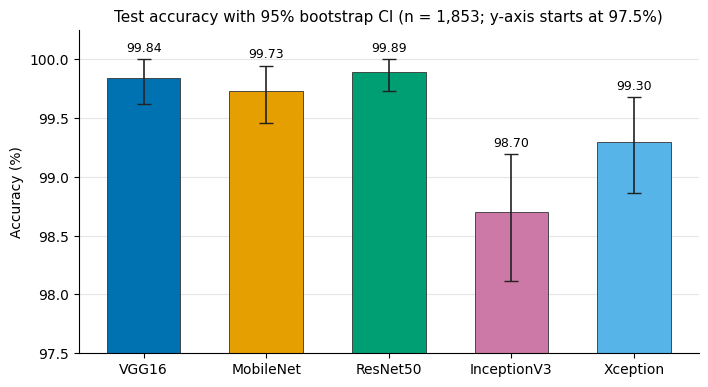

saved figures/results_macro_f1.png


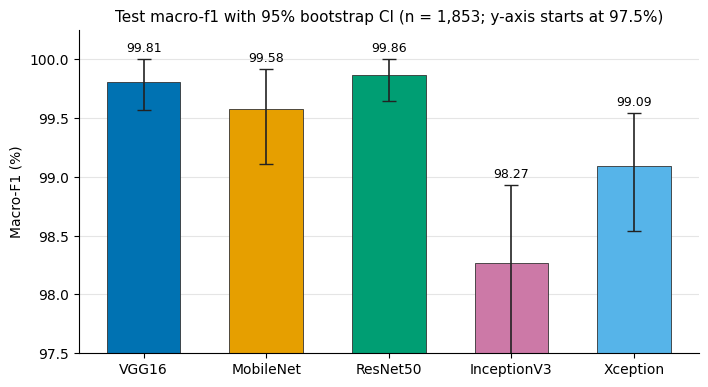

In [11]:
def ci_bars(metric, lo, hi, title, fname):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    v = 100 * res[metric].to_numpy()
    err = np.vstack([v - 100 * res[lo].to_numpy(), 100 * res[hi].to_numpy() - v])
    ax.bar(MODELS, v, color=[MODEL_COLOR[m] for m in MODELS], width=0.6, edgecolor="#333333", lw=0.6)
    ax.errorbar(MODELS, v, yerr=err, fmt="none", ecolor="#222222", capsize=5, lw=1.2)
    for i, (x, h) in enumerate(zip(MODELS, 100 * res[hi].to_numpy())):
        ax.text(i, h + 0.04, f"{v[i]:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(97.5, 100.25)
    ax.set_ylabel(f"{title} (%)")
    ax.set_title(f"Test {title.lower()} with 95% bootstrap CI (n = 1,853; y-axis starts at 97.5%)")
    ax.yaxis.grid(True, color="#E5E5E5")
    ax.set_axisbelow(True)
    save(fig, fname)
    plt.show()

ci_bars("accuracy", "acc_lo", "acc_hi", "Accuracy", "results_accuracy.png")
ci_bars("macro_f1", "f1_lo", "f1_hi", "Macro-F1", "results_macro_f1.png")

### 7.3 Confusion matrices

saved figures/confusion_matrices.png


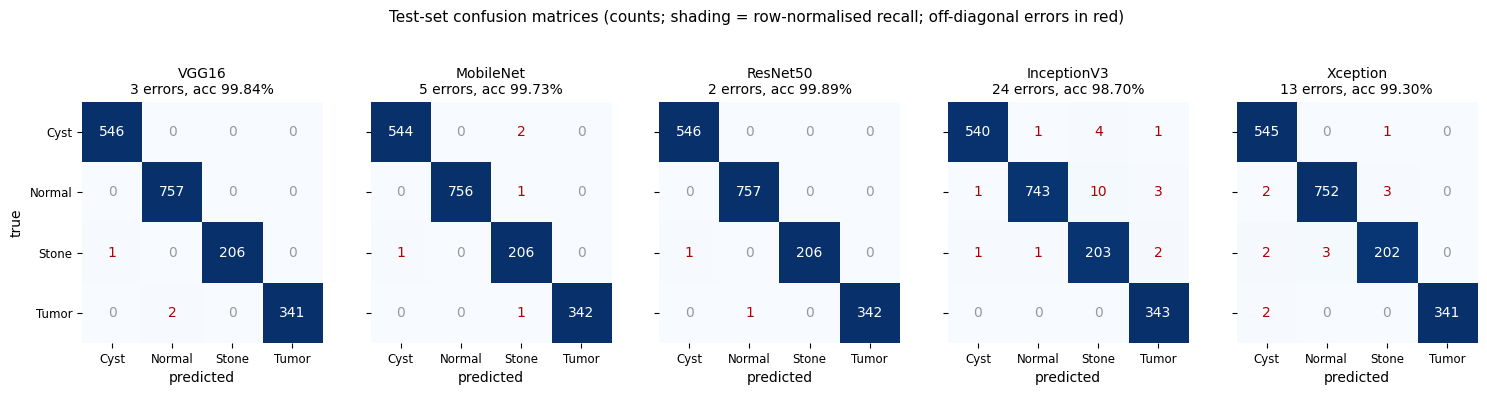

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.9))
for ax, m in zip(axes, MODELS):
    cm = np.array(metrics[m]["confusion_matrix"])
    norm = cm / cm.sum(1, keepdims=True)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10,
                    color="white" if norm[i, j] > 0.5 else ("#B00000" if cm[i, j] else "#999999"))
    ax.set_xticks(range(K), CLASSES, fontsize=8.5)
    ax.set_yticks(range(K), CLASSES if m == MODELS[0] else [""] * K, fontsize=8.5)
    ax.set_xlabel("predicted")
    ax.set_title(f"{m}\n{res.loc[m, 'errors']} errors, acc {100 * res.loc[m, 'accuracy']:.2f}%", fontsize=10)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_ylabel("true")
fig.suptitle("Test-set confusion matrices (counts; shading = row-normalised recall; off-diagonal errors in red)",
             y=1.04, fontsize=11)
save(fig, "confusion_matrices.png")
plt.show()

### 7.4 Per-class F1

saved figures/per_class_f1.png


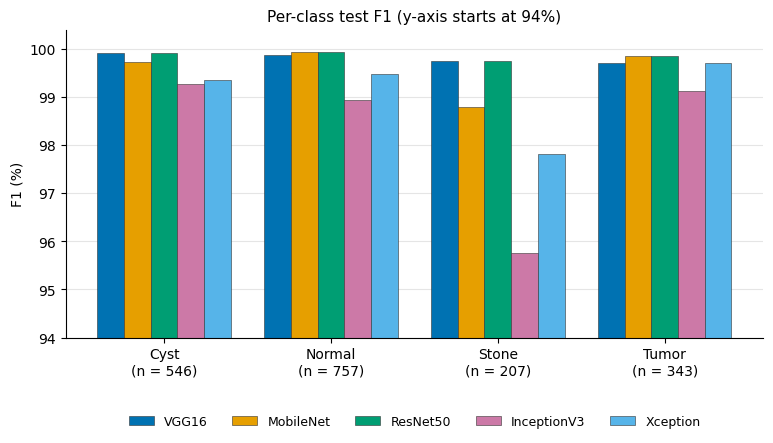

,Cyst_f1,Normal_f1,Stone_f1,Tumor_f1
model,,,,
VGG16,99.91,99.87,99.76,99.71
MobileNet,99.73,99.93,98.80,99.85
ResNet50,99.91,99.93,99.76,99.85
InceptionV3,99.26,98.93,95.75,99.13
Xception,99.36,99.47,97.82,99.71


In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.16
x = np.arange(K)
for i, m in enumerate(MODELS):
    ax.bar(x + (i - 2) * w, 100 * res.loc[m, [f"{c}_f1" for c in CLASSES]].to_numpy(), w,
           color=MODEL_COLOR[m], label=m, edgecolor="#333333", lw=0.4)
ax.set_xticks(x, [f"{c}\n(n = {metrics['VGG16'][c + '_support']})" for c in CLASSES])
ax.set_ylim(94, 100.4)
ax.set_ylabel("F1 (%)")
ax.set_title("Per-class test F1 (y-axis starts at 94%)")
ax.yaxis.grid(True, color="#E5E5E5")
ax.set_axisbelow(True)
ax.legend(ncol=5, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.33))
save(fig, "per_class_f1.png")
plt.show()

(100 * res[[f"{c}_f1" for c in CLASSES]]).round(2)

### 7.5 ROC curves (one-vs-rest, computed from `predictions.csv`)

All the AUCs are at or above 0.9997, so on a linear axis every curve sits in the top-left corner. The false-positive rate is therefore drawn on a **log scale**, which shows where the curves actually differ.

saved figures/roc_curves.png


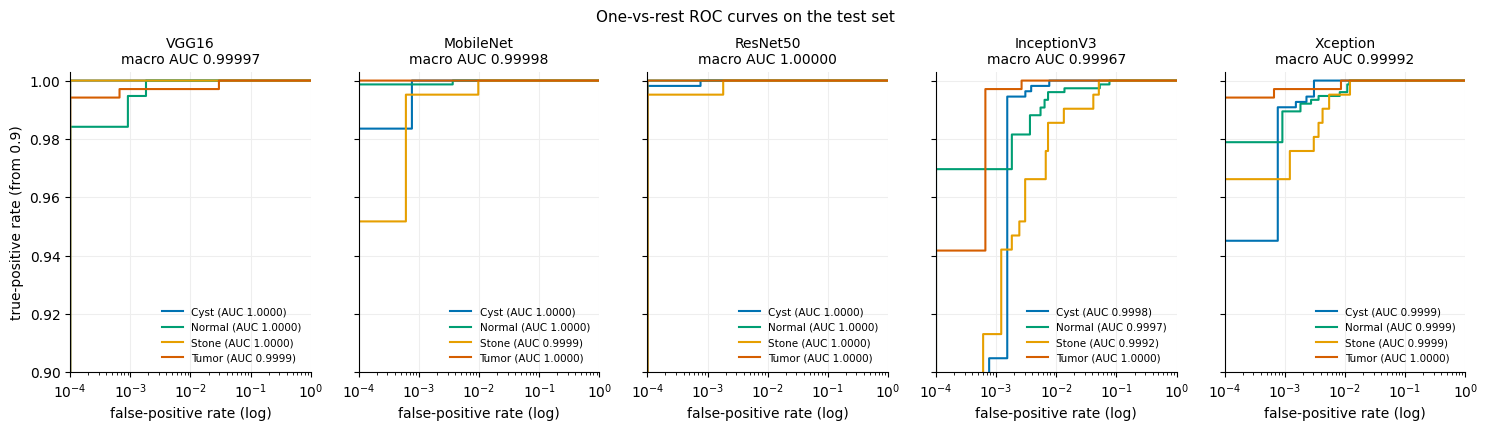

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.9), sharey=True)
for ax, m in zip(axes, MODELS):
    for c in CLASSES:
        fpr, tpr, auc = roc[m][c]
        ax.step(np.clip(fpr, 1e-4, 1), tpr, where="post", color=CLASS_COLOR[c], lw=1.5,
                label=f"{c} (AUC {auc:.4f})")
    ax.set_xscale("log")
    ax.set_xlim(1e-4, 1)
    ax.set_ylim(0.9, 1.003)
    ax.set_xlabel("false-positive rate (log)")
    ax.set_title(f"{m}\nmacro AUC {res.loc[m, 'roc_auc']:.5f}", fontsize=10)
    ax.legend(fontsize=7.5, loc="lower right", frameon=False)
    ax.grid(True, color="#EEEEEE")
axes[0].set_ylabel("true-positive rate (from 0.9)")
fig.suptitle("One-vs-rest ROC curves on the test set", y=1.04, fontsize=11)
save(fig, "roc_curves.png")
plt.show()

### 7.6 Training curves of the final refit (10 epochs, best hyperparameters)

saved figures/training_curves.png


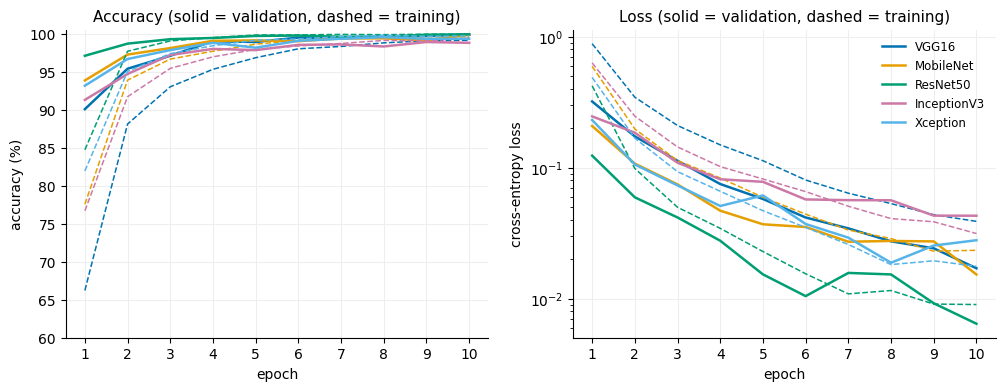

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m in MODELS:
    h = history[m]
    ep = h["epoch"] + 1
    axes[0].plot(ep, 100 * h["val_accuracy"], color=MODEL_COLOR[m], lw=1.8, label=f"{m} val")
    axes[0].plot(ep, 100 * h["accuracy"], color=MODEL_COLOR[m], lw=1.1, ls="--")
    axes[1].plot(ep, h["val_loss"], color=MODEL_COLOR[m], lw=1.8, label=m)
    axes[1].plot(ep, h["loss"], color=MODEL_COLOR[m], lw=1.1, ls="--")
axes[0].set_ylabel("accuracy (%)")
axes[0].set_ylim(60, 100.5)
axes[1].set_ylabel("cross-entropy loss")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_xticks(range(1, 11))
    ax.grid(True, color="#EEEEEE")
axes[0].set_title("Accuracy (solid = validation, dashed = training)")
axes[1].set_title("Loss (solid = validation, dashed = training)")
axes[1].legend(frameon=False, fontsize=8.5)
save(fig, "training_curves.png")
plt.show()

Training accuracy is below validation accuracy for most epochs. This is expected, because dropout is active during training and inactive during evaluation. For four of the five models, validation loss is still falling at epoch 10, so a longer refit would probably not hurt. We kept the 10-epoch refit fixed for every model.

### 7.7 Hyperparameter search and selected configuration

In [16]:
best = pd.DataFrame({
    "dense units": [metrics[m]["best_hyperparameters"]["dense_units"] for m in MODELS],
    "dropout": [round(metrics[m]["best_hyperparameters"]["dropout_rate"], 1) for m in MODELS],
    "learning rate": [metrics[m]["best_hyperparameters"]["learning_rate"] for m in MODELS],
    "best trial": [metrics[m]["best_trial"] for m in MODELS],
    "tuner val acc (mean of 3)": [round(metrics[m]["tuner_best_val_accuracy"], 4) for m in MODELS],
    "val acc after refit": [round(metrics[m]["final_val_accuracy"], 4) for m in MODELS],
    "feature dim": [metrics[m]["feature_dim"] for m in MODELS],
    "total minutes (CPU)": summary["minutes"].to_numpy(),
}, index=MODELS)
best

,dense units,dropout,learning rate,best trial,tuner val acc (mean of 3),val acc after refit,feature dim,total minutes (CPU)
VGG16,640,0.3,0.0001,06,0.9989,0.9984,512,38.6
MobileNet,640,0.3,0.0001,06,0.9956,0.9984,1024,16.7
ResNet50,640,0.2,0.0001,01,0.9982,0.9989,2048,37.3
InceptionV3,640,0.3,0.0001,06,0.9897,0.9878,2048,22.1
Xception,640,0.2,0.0001,01,0.9954,0.9931,2048,29.9


saved figures/tuner_trials.png


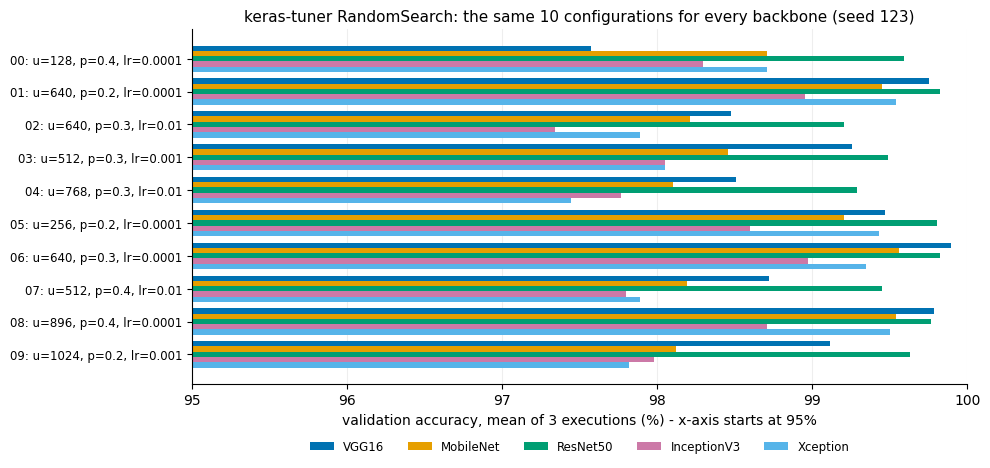

In [17]:
cfg = trials["VGG16"][["trial", "dense_units", "dropout_rate", "learning_rate"]].copy()
cfg["dropout_rate"] = cfg["dropout_rate"].round(1)
for m in MODELS:
    assert (trials[m][["dense_units", "learning_rate"]].to_numpy() == cfg[["dense_units", "learning_rate"]].to_numpy()).all()
labels = [f"{r.trial}: u={r.dense_units}, p={r.dropout_rate}, lr={r.learning_rate:g}" for r in cfg.itertuples()]

fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(cfg))
h = 0.16
for i, m in enumerate(MODELS):
    ax.barh(y + (i - 2) * h, 100 * trials[m]["val_accuracy"], h, color=MODEL_COLOR[m], label=m)
ax.set_yticks(y, labels, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlim(95, 100)
ax.set_xlabel("validation accuracy, mean of 3 executions (%) - x-axis starts at 95%")
ax.set_title("keras-tuner RandomSearch: the same 10 configurations for every backbone (seed 123)")
ax.legend(frameon=False, fontsize=8.5, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.13))
ax.xaxis.grid(True, color="#EEEEEE")
ax.set_axisbelow(True)
save(fig, "tuner_trials.png")
plt.show()

## 8. Discussion

**All five networks reach about 99% under the image-level protocol.** ResNet50 (2 errors out of 1,853), VGG16 (3) and MobileNet (5) are the top three. Their bootstrap intervals overlap heavily, so this test set cannot separate them. Xception (13 errors) and InceptionV3 (24 errors) are clearly lower. Most of InceptionV3's errors are Normal slices predicted as Stone (10), which lowers Stone precision to 0.935.

**Stone is the hardest class for every model.** It is the smallest class (207 test images), and a small calcification is a fine detail to resolve after downsampling to 150×150. This pattern also appears, much more strongly, in the scan-level evaluation.

**High image-level accuracy is not generalisation.** The scores come from a held-out test set, with validation-only model selection, each network's own preprocessing and label-based metrics. They do not, however, measure performance on new patients, because the image-level split places slices of the same scan in training and test (Section 9).

**Hyperparameters.** With a fixed tuner seed, every backbone was offered the same ten configurations. For all five, the winner had 640 units and a learning rate of 1e-4 (dropout 0.2 or 0.3). The learning rate matters most: every 1e-2 trial is among the four weakest for every backbone, and every backbone's best trial uses 1e-4. Within the 1e-4 trials, the differences are a few tenths of a percent.

## 9. Limitations: image-level leakage

**These numbers measure recognition of familiar scans, not performance on new patients.**

* **Slices of the same scan appear in training and test.** Consecutive file numbers in the dataset are neighbouring slices of one CT scan. From slice order and image similarity, 204 scan groups can be recovered (`results/scan_groups.csv`). Under the image-level split used here, **1,852 of the 1,853 test images (99.9%) come from a scan that also has slices in the training set.**
* **Most test images have a near-copy in training.** **97.4%** of test images (1,805) have a near-identical training image, with a correlation of at least 0.995 between 32×32 thumbnails. The median best correlation is 0.9992. Removing byte-identical duplicates (Section 5) does not address this.
* **The confidence intervals are too narrow.** The bootstrap resamples test images as if they were independent. Slices of one scan are strongly correlated, so the effective sample size is closer to the number of scans than to the number of images.
* **One split, one seed, one dataset.** The results come from a single seed and a single split, with no external validation on scans from another hospital. The dataset has no patient identifiers.

**What happens when whole scans are held out.** The same five frozen backbones, evaluated with group-level 5-fold cross-validation in which no scan is ever split between training and test, score only **56–67%** accuracy. The best model of the full study, an ensemble of two fine-tuned MobileNets, reaches **about 81%** (0.814, 95% CI 0.758–0.865). See `results/REPORT.md` and `results/IMPROVEMENTS.md`. Use those numbers for any claim about generalisation. The figure below sets the two protocols side by side.

split summary: test from a scan seen in training 99.9%, near-identical 97.4%
saved figures/leakage_context.png


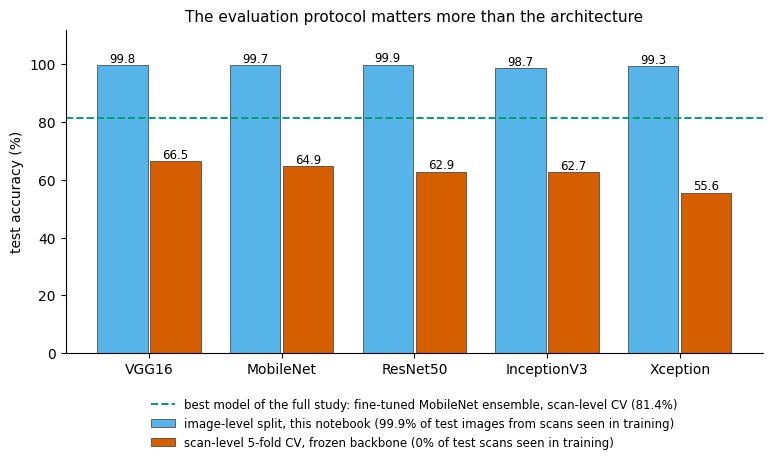

In [18]:
pooled = pd.read_csv(ROOT / "results" / "pooled_metrics.csv")
grp = pooled[pooled["protocol"] == "group-level CV"].set_index("model").loc[MODELS, "accuracy"]
print(f"split summary: test from a scan seen in training {split_summary['test_from_scan_in_train_pct']:.1f}%, "
      f"near-identical {split_summary['test_near_identical_in_train_pct']:.1f}%")

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(MODELS))
ax.bar(x - 0.2, 100 * res["accuracy"], 0.38, color=OI["sky"], edgecolor="#333333", lw=0.5,
       label="image-level split, this notebook (99.9% of test images from scans seen in training)")
ax.bar(x + 0.2, 100 * grp.to_numpy(), 0.38, color=OI["vermillion"], edgecolor="#333333", lw=0.5,
       label="scan-level 5-fold CV, frozen backbone (0% of test scans seen in training)")
for i in range(len(MODELS)):
    ax.text(i - 0.2, 100 * res["accuracy"].iloc[i] + 1, f"{100 * res['accuracy'].iloc[i]:.1f}", ha="center", fontsize=8.5)
    ax.text(i + 0.2, 100 * grp.iloc[i] + 1, f"{100 * grp.iloc[i]:.1f}", ha="center", fontsize=8.5)
ax.axhline(81.4, color=OI["green"], ls="--", lw=1.4,
           label="best model of the full study: fine-tuned MobileNet ensemble, scan-level CV (81.4%)")
ax.set_xticks(x, MODELS)
ax.set_ylim(0, 112)
ax.set_ylabel("test accuracy (%)")
ax.set_title("The evaluation protocol matters more than the architecture")
ax.legend(frameon=False, fontsize=8.5, loc="lower center", bbox_to_anchor=(0.5, -0.33))
save(fig, "leakage_context.png")
plt.show()

Note that the scan-level numbers come from a different, earlier configuration: 224×224 input, average pooling, and a head chosen by validation macro-F1 within each fold (`results/REPORT.md`). The comparison isolates the effect of the evaluation protocol, not of every hyperparameter.

## 10. Reproducibility

| Item | Value |
|---|---|
| Training script | `scripts/run_image_level.py` (resumable; `--sanity-check`, `--report-only`) |
| Shared code | `src/kidney_tl/image_level.py` (split, metrics), `src/kidney_tl/image_level_pipeline.py` (decoding, preprocessing, backbones) |
| Container | `docker/Dockerfile.image_level`: TensorFlow 2.15.0 (CPU), keras-tuner 1.4.7, ImageNet weights baked in |
| Colab | `notebooks/image_level_colab.ipynb` (GPU; `MODE="cached"` runs the script, `MODE="end_to_end"` trains backbone + head in one Keras model) |
| Seeds | split 123, tuner 123, shuffling of training batches 123, bootstrap 123 |
| Hardware used | CPU only, 3–4 cores, 2.5–3 GB container memory limit, about 2.6 h for all five models |

```bash
python scripts/download_data.py --source huggingface          # or Kaggle (default)
docker build -f docker/Dockerfile.image_level -t kidney-image-level:2.15 docker/
docker run --rm --memory=3g --memory-swap=3g --cpus=4 \
    -v "$PWD":/work -w /work kidney-image-level:2.15 python scripts/run_image_level.py
```

This notebook itself needs only `pandas`, `numpy` and `matplotlib`, and runs in a few seconds:

```bash
jupyter nbconvert --to notebook --execute --inplace notebooks/kidney_ct_transfer_learning.ipynb
```

In [19]:
import platform
import matplotlib
print("environment of the training run:", environment)
print(f"this notebook: python {platform.python_version()}, numpy {np.__version__}, "
      f"pandas {pd.__version__}, matplotlib {matplotlib.__version__}")
print("figures written:", sorted(p.name for p in FIG.glob("*.png")))

environment of the training run: {'tensorflow': '2.15.0', 'keras_tuner': '1.4.7', 'numpy': '1.26.4', 'pandas': '2.2.3', 'python': '3.11.0rc1', 'cpu_count': 12, 'intra_threads': '3', 'batch_size': 16}
this notebook: python 3.11.0rc1, numpy 1.26.4, pandas 2.2.3, matplotlib 3.9.2
figures written: ['confusion_matrices.png', 'leakage_context.png', 'per_class_f1.png', 'pipeline.png', 'results_accuracy.png', 'results_macro_f1.png', 'roc_curves.png', 'sample_images.png', 'split.png', 'training_curves.png', 'tuner_trials.png']


## 11. Conclusion

With a held-out test set, validation-only model selection, per-network preprocessing and label-based metrics, all five frozen ImageNet CNNs reach **98.7–99.9%** test accuracy on an image-level split of the kidney CT dataset. ResNet50 is best at 99.89%, followed by VGG16 (99.84%) and MobileNet (99.73%), and the top three cannot be separated on this test set.

It does not, however, measure generalisation. Almost every test image has a neighbouring slice of the same scan in the training set. When whole scans are held out, the same models fall to 56–67%, and a fine-tuned ensemble reaches about 81%. Image-level accuracy on this dataset should be read as a measure of within-scan recognition. Future work on it should split by scan, or better by patient, and report cluster-aware confidence intervals.

## 12. References

1. M. N. Islam, M. Hasan, M. K. Hossain, M. G. R. Alam, M. Z. Uddin and A. Soylu, "Vision transformer and explainable transfer learning models for auto detection of kidney cyst, stone and tumor from CT-radiography," *Scientific Reports*, vol. 12, art. 11440, 2022. doi:[10.1038/s41598-022-15634-4](https://doi.org/10.1038/s41598-022-15634-4)
2. J. Deng, W. Dong, R. Socher, L.-J. Li, K. Li and L. Fei-Fei, "ImageNet: A large-scale hierarchical image database," in *Proc. IEEE CVPR*, 2009, pp. 248–255. doi:[10.1109/CVPR.2009.5206848](https://doi.org/10.1109/CVPR.2009.5206848)
3. K. Simonyan and A. Zisserman, "Very deep convolutional networks for large-scale image recognition," in *Proc. ICLR*, 2015. [arXiv:1409.1556](https://arxiv.org/abs/1409.1556)
4. A. G. Howard, M. Zhu, B. Chen, D. Kalenichenko, W. Wang, T. Weyand, M. Andreetto and H. Adam, "MobileNets: Efficient convolutional neural networks for mobile vision applications," 2017. [arXiv:1704.04861](https://arxiv.org/abs/1704.04861)
5. K. He, X. Zhang, S. Ren and J. Sun, "Deep residual learning for image recognition," in *Proc. IEEE CVPR*, 2016, pp. 770–778. doi:[10.1109/CVPR.2016.90](https://doi.org/10.1109/CVPR.2016.90)
6. C. Szegedy, V. Vanhoucke, S. Ioffe, J. Shlens and Z. Wojna, "Rethinking the Inception architecture for computer vision," in *Proc. IEEE CVPR*, 2016, pp. 2818–2826. doi:[10.1109/CVPR.2016.308](https://doi.org/10.1109/CVPR.2016.308)
7. F. Chollet, "Xception: Deep learning with depthwise separable convolutions," in *Proc. IEEE CVPR*, 2017, pp. 1251–1258. doi:[10.1109/CVPR.2017.195](https://doi.org/10.1109/CVPR.2017.195)
8. T. O'Malley, E. Bursztein, J. Long, F. Chollet, H. Jin, L. Invernizzi et al., "KerasTuner," 2019. https://github.com/keras-team/keras-tuner
9. S. Kapoor and A. Narayanan, "Leakage and the reproducibility crisis in machine-learning-based science," *Patterns*, vol. 4, no. 9, art. 100804, 2023. doi:[10.1016/j.patter.2023.100804](https://doi.org/10.1016/j.patter.2023.100804)
10. E. Yagis, S. W. Atnafu, A. García Seco de Herrera, C. Marzi, R. Scheda, M. Giannelli, C. Tessa, L. Citi and S. Diciotti, "Effect of data leakage in brain MRI classification using 2D convolutional neural networks," *Scientific Reports*, vol. 11, art. 22544, 2021. doi:[10.1038/s41598-021-01681-w](https://doi.org/10.1038/s41598-021-01681-w)
11. R. Maharjan and S. Sitaula, "Convolutional neural network architectures for detection of kidney abnormalities: A comparative analysis," *Research Annals of Xavier's Nepal*, Issue VI, 2024.